https://github.com/bmoscon/cryptofeed

In [7]:
import pandas as pd
from market_data_real import MarketDataCollector

In [8]:
collector = MarketDataCollector(
    markets=[
        (
            "BINANCE",
            "BTC-USDT"
        ),
        (
            "HYPERLIQUID",
            "BTC-USD-PERP"
        ),
    ],

    record_raw=True,
)

In [ ]:
await collector.collect(3000)

Added BINANCE BTC-USDT
Added HYPERLIQUID BTC-USD-PERP

Started 2 market(s).
Raw PCAP directory: data/raw/pcap/20260927T080441_437871Z
Stopping feeds...
Flushing Parquet storage...
Stopped.


In [28]:
collector.stats 

{'markets': {'BINANCE:BTC-USDT': {'trades': 3607, 'book_updates': 6151},
  'HYPERLIQUID:BTC-USD-PERP': {'trades': 2252, 'book_updates': 119}},
 'queue_size': 0,
 'dropped_events': 0,
 'record_raw': True,
 'pcap_path': 'data/raw/pcap/20260927T080441_437871Z'}

In [86]:
trades = pd.read_parquet(
    "data/raw/normalised/BINANCE/BTC-USDT/trades/"
)
books_bin_raw = pd.read_parquet("data/raw/normalised/BINANCE/BTC-USDT")

In [66]:
books_bin = books_bin.dropna()
books_bin['exchange_timestamp'] = pd.to_datetime(books_bin['exchange_timestamp'], utc=True, unit = 's').dt.tz_convert('Australia/Sydney')
books_bin = books_bin.set_index('exchange_timestamp')
books_bin.tail()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,receipt_timestamp
exchange_timestamp,,,,,,,,,,,,
2026-09-27 18:14:40.914000034+10:00,BINANCE,BTC-USDT,84803.99,3.37345,84804.0,5.01307,84803.995,0.01,0.001179,-0.195507,84803.994022,1.790497e+09
2026-09-27 18:14:41.013999939+10:00,BINANCE,BTC-USDT,84803.99,3.37345,84804.0,3.74835,84803.995,0.01,0.001179,-0.052641,84803.994737,1.790497e+09
2026-09-27 18:14:41.114000082+10:00,BINANCE,BTC-USDT,84803.99,3.82534,84804.0,3.74835,84803.995,0.01,0.001179,0.010165,84803.995051,1.790497e+09
2026-09-27 18:14:41.213999987+10:00,BINANCE,BTC-USDT,84803.99,3.82534,84804.0,3.74835,84803.995,0.01,0.001179,0.010165,84803.995051,1.790497e+09
2026-09-27 18:14:41.313999891+10:00,BINANCE,BTC-USDT,84803.99,3.82569,84804.0,3.74835,84803.995,0.01,0.001179,0.010211,84803.995051,1.790497e+09


In [61]:
from datetime import datetime, timezone
from zoneinfo import ZoneInfo

In [85]:
books_hyper_raw = pd.read_parquet("data/raw/normalised/HYPERLIQUID/BTC-USD-PERP")

In [80]:
books_hyper = books_hyper.dropna()
books_hyper['exchange_timestamp'] = pd.to_datetime(books_hyper['exchange_timestamp'], utc=True, unit = 's').dt.tz_convert('Australia/Sydney')
books_hyper = books_hyper.set_index('exchange_timestamp')
books_hyper.tail()

,exchange,symbol,bid,bid_size,ask,ask_size,mid,spread,spread_bps,imbalance,microprice,receipt_timestamp
exchange_timestamp,,,,,,,,,,,,
2026-09-27 18:14:19.368000031+10:00,HYPERLIQUID,BTC-USD-PERP,84795.0,1.39860,84796.0,9.13901,84795.5,1.0,0.117931,-0.734551,84795.132725,1.790497e+09
2026-09-27 18:14:24.325000048+10:00,HYPERLIQUID,BTC-USD-PERP,84795.0,0.02029,84796.0,11.02179,84795.5,1.0,0.117931,-0.996325,84795.001838,1.790497e+09
2026-09-27 18:14:29.684000015+10:00,HYPERLIQUID,BTC-USD-PERP,84789.0,3.24420,84790.0,6.06625,84789.5,1.0,0.117939,-0.303106,84789.348447,1.790497e+09
2026-09-27 18:14:35.088000059+10:00,HYPERLIQUID,BTC-USD-PERP,84789.0,3.52666,84790.0,6.96541,84789.5,1.0,0.117939,-0.327748,84789.336126,1.790497e+09
2026-09-27 18:14:40.466000080+10:00,HYPERLIQUID,BTC-USD-PERP,84789.0,4.25813,84790.0,6.20354,84789.5,1.0,0.117939,-0.185956,84789.407022,1.790497e+09


In [92]:
books_hyper.columns

Index(['exchange', 'symbol', 'bid', 'bid_size', 'ask', 'ask_size', 'mid',
       'spread', 'spread_bps', 'imbalance', 'microprice', 'receipt_timestamp'],
      dtype='str')

In [ ]:
books_hyper['mid']

exchange_timestamp
2026-09-27 17:54:12.647000074+10:00    84635.5
2026-09-27 17:54:15.920000076+10:00    84635.5
2026-09-27 17:54:21.483000040+10:00    84638.5
2026-09-27 17:59:23.115000010+10:00    84749.5
2026-09-27 17:59:26.996000051+10:00    84749.5
                                        ...   
2026-09-27 18:14:19.368000031+10:00    84795.5
2026-09-27 18:14:24.325000048+10:00    84795.5
2026-09-27 18:14:29.684000015+10:00    84789.5
2026-09-27 18:14:35.088000059+10:00    84789.5
2026-09-27 18:14:40.466000080+10:00    84789.5
Name: mid, Length: 119, dtype: float64

resampled to 100ms

In [87]:
b = books_bin_raw.copy()

b["datetime"] = pd.to_datetime(
    b["receipt_timestamp"],
    unit="s",
    utc=True
)

b = (
    b
    .set_index("datetime")
    .sort_index()
)

In [88]:
h = books_hyper_raw.copy()

h["datetime"] = pd.to_datetime(
    h["receipt_timestamp"],
    unit="s",
    utc=True
)

h = (
    h
    .set_index("datetime")
    .sort_index()
)

In [ ]:
b_100ms = (
    b[["mid"]]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "binance_mid"})
)

h_100ms = (
    h[["mid"]]
    .resample("100ms")
    .last()
    .ffill()
    .rename(columns={"mid": "hyperliquid_mid"})
)

In [90]:
df = b_100ms.join(
    h_100ms,
    how="inner"
)

<Axes: title={'center': 'Hyperliquid - Binance BTC Mid Difference (bps)'}, xlabel='datetime'>

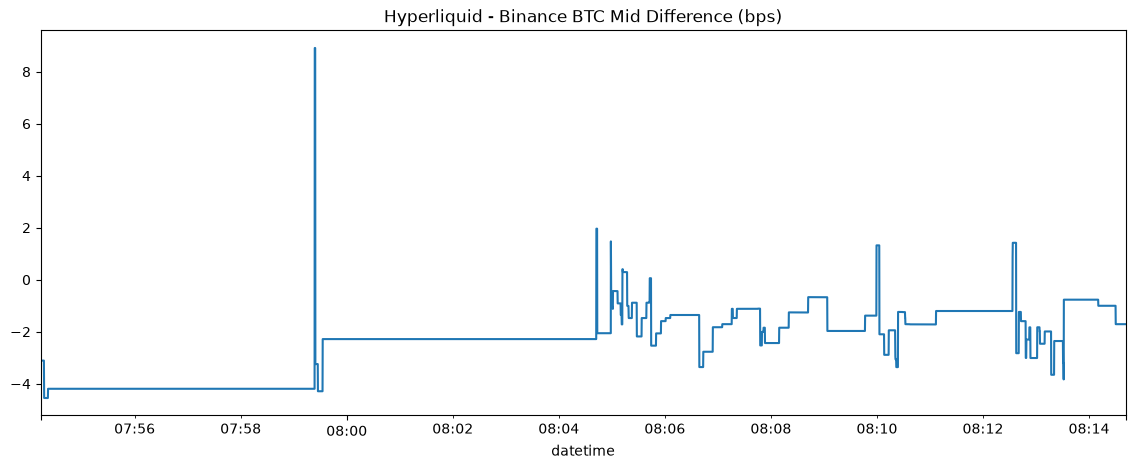

In [ ]:
df["mid_diff"] = (
    df["hyperliquid_mid"]
    - df["binance_mid"]
)

df["reference_mid"] = (
    df["hyperliquid_mid"]
    + df["binance_mid"]
) / 2

df["mid_diff_bps"] = (
    df["hyperliquid_mid"]
    - df["binance_mid"]
) / df["reference_mid"] * 10_000

df["mid_diff_bps"].plot(
    figsize=(14, 5),
    title="Hyperliquid - Binance BTC Mid Difference (bps)"
)

<Axes: xlabel='datetime'>

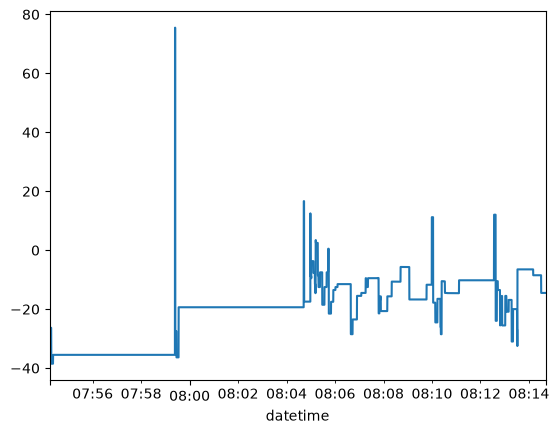

In [98]:
df['mid_diff'].plot()